In [29]:
import os
from tqdm import tqdm
import pandas as pd
import numpy as np
from pathlib import Path
from glob import glob

# TODO: Fix ProteoBench dependency
from SCI_py.data.parse import df_to_anndata, align_obs_across_anndata
from SCI_py.data.read import load_spectronaut

tqdm.pandas()

In [35]:
condition_setup_wyss = pd.read_csv(
    '/public/conode53/sam/SCI/Bogdan/spectronaut/mixture/directdia/2/Bogdan_01192026_ConditionSetup.tsv',
    sep='\t'
)
condition_setup_wyss['Condition'] = condition_setup_wyss.apply(
    lambda x: x['#'],
    axis=1
)
condition_setup_wyss['Replicate'] = 1

condition_setup_wyss.to_csv(
    '/public/conode53/sam/SCI/Bogdan/spectronaut/mixture/directdia/3/conditions.tsv',
    sep='\t',
    index=False
)

There was some discussion about the search strategy of Spectronaut.

The strategy is as follows:
Each plate was searched independently with the DirectDIA+ approach and afterwards all SNE result files were combined naively with the SNE combine method. However, since it is believed different search spaces are created within each plate, combining them as such will result in inaccurate FDR calculations (and quantifications?).

Therefore, it was suggested to use the data from the separate searches and make them comparable by only using proteotypic peptides and perform the protein inference/quantification externally ourselves.

Here, the impact of the SNE combine on the 9 SNE files is investigated and quantified

In [49]:
ROOT = '/public/conode53/sam/SCI'

reports = {
    name: load_spectronaut(
        glob(
            os.path.join(
                ROOT,
                name,
                'spectronaut',
                'human',
                'directdia',
                '*',
                '*Report (Normal).tsv'
            )
        )[0] 
    )
    for name in [
        'Bogdan',
        'Claudia',
        'Erwin',
        'Jeewan',
        'Karl_plate_5',
        'Kelly',
        'KI_Akos',
        'KI_Akos_11'
    ]
}

100%|██████████| 2605858/2605858 [00:16<00:00, 162766.88it/s]


In [3]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

METADATA_PATH = os.path.join(
    ROOT_OUT,
    'metadata',
    'metadata.parquet'
)

metadata = pd.read_parquet(
    METADATA_PATH
)

Output directory: /home/sam/SCI/SCI/Data


In [ ]:
reports = {
    k: v.merge(metadata, on=['plate_id', 'sample_name']) for k, v in reports.items()
}

In [5]:
cols_protpept_metadata = [
    'PG.ProteinGroups',
    'PG.ProteinAccessions',
    'PEP.StrippedSequence',
    'PEP.IsProteotypic',
    'EG.ModifiedSequence',
    'FG.Charge',
    'FG.LabeledSequence',
    'FG.PrecursorIon'
]
cols_idconf = [
    'PG.Pvalue',
    'PG.Qvalue',
    'FG.Qvalue',
    'EG.GlobalPrecursorQvalue',
    'PG.Cscore'
]
cols_quant = [
    'PG.Quantity',
    'EG.TargetQuantity (Settings)',
    'EG.ReferenceQuantity (Settings)',
    'EG.TotalQuantity (Settings)',
    'FG.Quantity',
]
cols_peptfeatures = [
    # Retention time
    'EG.ApexRT',
    'EG.RTPredicted',
    'EG.iRTEmpirical',
    'EG.iRTPredicted',
    
    # MS2 features
    'FG.PrecWindowNumber',
    'FG.CScore',
]
cols_metadata = [
    'sample_name',
    'plate_id',
    'plate_idx',
    'source name',
    'comment[X position]',
    'comment[Y position]',
    'comment[Plate Number]',
    'comment[Gradient time]',
    'comment[thawing timepoint]',
    'comment[plate arrival]',
    'injection_order',
    'institute_name',
    'Reinjection',
    'Diameter',
    'Elongation',
    'Circularity',
    'Doublet',
    'Dividing',
    'Dying',
    'CellInBlank',
    'comment[plate arrival]_date',
    'comment[plate arrival]_time', 'comment[plate arrival]_datetime',
    'comment[Gradient time]_date', 'comment[Gradient time]_time',
    'comment[Gradient time]_datetime', 'instrument_type'
]

col_sample_index = ['sample_id']

var_cols = cols_protpept_metadata + cols_idconf + cols_peptfeatures

In [6]:
adata_precursor, X_precursor_qc = df_to_anndata(
    df_individual,
    feature_col = 'FG.PrecursorIon',
    value_col   = 'EG.TotalQuantity (Settings)',
    sample_col  = 'sample_id',
    obs_cols    = cols_metadata,
    var_cols    = var_cols,
)

adata_precursor.layers['X_log2'] = np.log2(adata_precursor.X)

In [8]:
import anndata
adata_precursor_og = anndata.io.read_h5ad('/home/sam/SCI/SCI/Data/AnnData/base/adata_precursor.h5ad')

In [11]:
adata_precursor
adata_precursor.obs['n_precursors'] = np.sum(~np.isnan(adata_precursor.X), axis=1)

In [16]:
adata_selection = adata_precursor_og[adata_precursor_og.obs['plate_id']=='Wyss_Astral_1']
adata_selection.obs['n_precursors'] = np.sum(~np.isnan(adata_selection.X), axis=1)

/tmp/ipykernel_2046327/1610080219.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_selection.obs['n_precursors'] = np.sum(~np.isnan(adata_selection.X), axis=1)


In [17]:
result = pd.merge(
    adata_precursor.obs,
    adata_selection.obs,
    on='sample_name'
)

In [18]:
result.columns.tolist()

['sample_name',
 'plate_id_x',
 'plate_idx_x',
 'source name_x',
 'comment[X position]_x',
 'comment[Y position]_x',
 'comment[Plate Number]_x',
 'comment[Gradient time]_x',
 'comment[thawing timepoint]_x',
 'comment[plate arrival]_x',
 'injection_order_x',
 'institute_name_x',
 'Reinjection_x',
 'Diameter_x',
 'Elongation_x',
 'Circularity_x',
 'Doublet_x',
 'Dividing_x',
 'Dying_x',
 'CellInBlank_x',
 'comment[plate arrival]_date_x',
 'comment[plate arrival]_time_x',
 'comment[plate arrival]_datetime_x',
 'comment[Gradient time]_date_x',
 'comment[Gradient time]_time_x',
 'comment[Gradient time]_datetime_x',
 'instrument_type_x',
 'n_precursors_x',
 'plate_id_y',
 'plate_idx_y',
 'source name_y',
 'comment[X position]_y',
 'comment[Y position]_y',
 'comment[Plate Number]_y',
 'comment[Gradient time]_y',
 'comment[thawing timepoint]_y',
 'comment[plate arrival]_y',
 'injection_order_y',
 'institute_name_y',
 'Reinjection_y',
 'Diameter_y',
 'Elongation_y',
 'Circularity_y',
 'Doublet_

<Axes: ylabel='Count'>

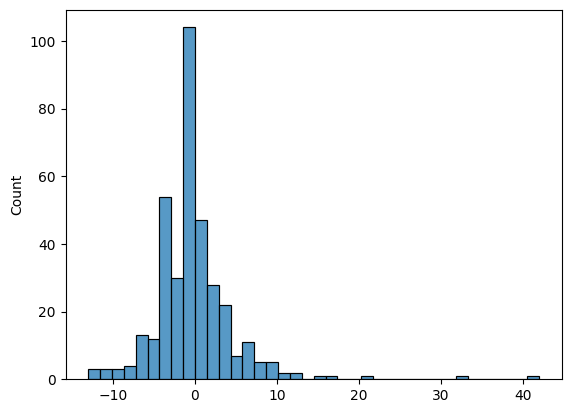

In [27]:
import seaborn as sns
sns.histplot(
    result.loc[:, [
        'n_precursors_x',
        'n_precursors_y'
    ]].apply(
        lambda x: (
            x['n_precursors_x'] - x['n_precursors_y']
        ),
    axis=1)
)

---

In [11]:

from SCI_py.plot.identifications import plot_counts_overview
from SCI_py.metrics.cvs import compute_cv_matrix
from SCI_py.plot.cvs import plot_cvs_overview
from SCI_py.plot.identifications import plot_identification_heatmap

In [9]:
adata_precursor.obs['n_precursors'] = np.sum(~np.isnan(adata_precursor.X), axis=1)
adata_protein.obs['n_proteins'] = np.sum(~np.isnan(adata_protein.X), axis=1)

adata_precursor_eval.obs['n_precursors'] = np.sum(~np.isnan(adata_precursor_eval.X), axis=1)
adata_protein_eval.obs['n_proteins'] = np.sum(~np.isnan(adata_protein_eval.X), axis=1)

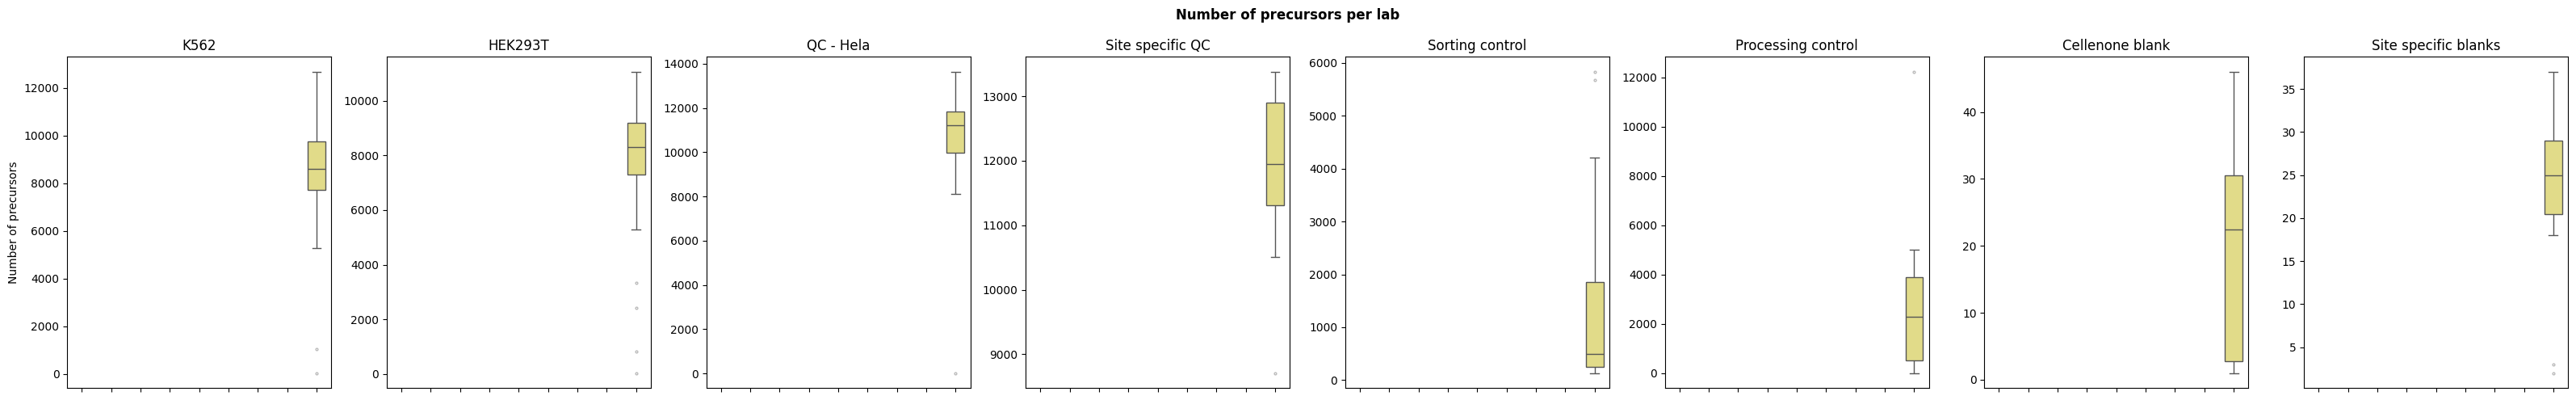

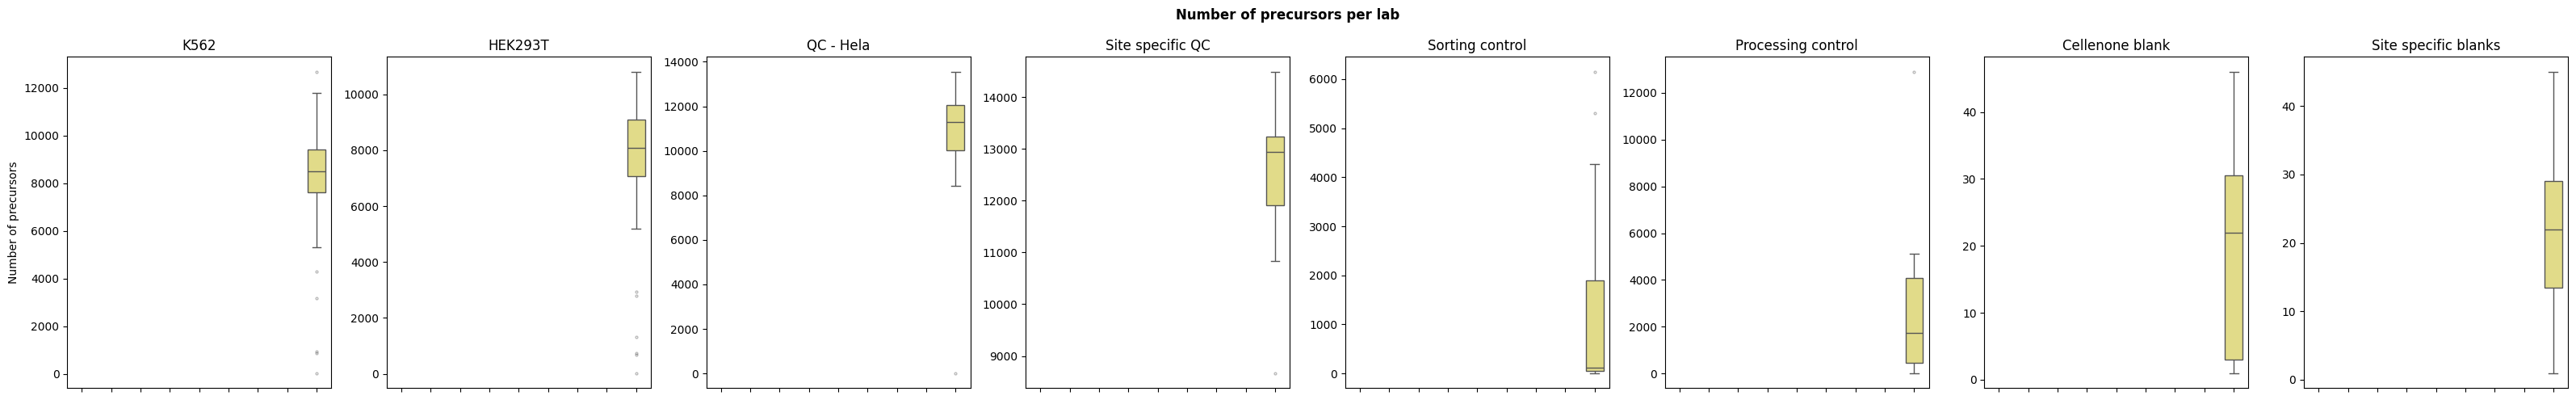

In [12]:
plot_counts_overview(
    adata=adata_precursor,
    count_col='n_precursors',
    split_conditions=True,
    show_xlabels=False,
    save_dir=False,
    filename='counts_overview_precursors_SPLIT.png',
    show=True
)

plot_counts_overview(
    adata=adata_precursor_eval,
    count_col='n_precursors',
    split_conditions=True,
    show_xlabels=False,
    save_dir=False,
    filename='counts_overview_precursors_SPLIT.png',
    show=True
)

In [15]:
merged = adata_precursor.obs.merge(
    adata_precursor_eval.obs,
    on='sample_id'
)

In [20]:
merged

,sample_name_x,plate_id_x,plate_idx_x,source name_x,comment[X position]_x,comment[Y position]_x,comment[Plate Number]_x,comment[Gradient time]_x,comment[thawing timepoint]_x,comment[plate arrival]_x,...,Dying_y,CellInBlank_y,comment[plate arrival]_date_y,comment[plate arrival]_time_y,comment[plate arrival]_datetime_y,comment[Gradient time]_date_y,comment[Gradient time]_time_y,comment[Gradient time]_datetime_y,instrument_type_y,n_precursors_y
sample_id,,,,,,,,,,,,,,,,,,,,,
cell_a_c10|BYU_timsTOF_1,cell_a_c10,BYU_timsTOF_1,timsTOF_3,K562,3,10,-1,20251010-060639,20251009-111666,20250922-155766,...,False,False,2025-09-22,15.951667,2025-09-22 15:57:06,2025-10-10,6.110833,2025-10-10 06:06:39,timsTOF,36
cell_a_c11|BYU_timsTOF_1,cell_a_c11,BYU_timsTOF_1,timsTOF_3,K562,3,11,-1,20251010-122637,20251009-111699,20250922-155799,...,False,False,2025-09-22,15.952500,2025-09-22 15:57:09,2025-10-10,12.443611,2025-10-10 12:26:37,timsTOF,7831
cell_a_c12|BYU_timsTOF_1,cell_a_c12,BYU_timsTOF_1,timsTOF_3,K562,3,12,-1,20251010-045739,20251009-111660,20250922-155760,...,False,False,2025-09-22,15.966667,2025-09-22 15:58:00,2025-10-10,4.960833,2025-10-10 04:57:39,timsTOF,9123
cell_a_c4|BYU_timsTOF_1,cell_a_c4,BYU_timsTOF_1,timsTOF_3,K562,3,4,-1,20251008-040917,20251009-111572,20250922-155672,...,False,False,2025-09-22,15.935278,2025-09-22 15:56:07,2025-10-08,4.154722,2025-10-08 04:09:17,timsTOF,9323
cell_a_c5|BYU_timsTOF_1,cell_a_c5,BYU_timsTOF_1,timsTOF_3,K562,3,5,-1,20251011-031150,20251009-111776,20250922-155876,...,False,False,2025-09-22,15.968611,2025-09-22 15:58:07,2025-10-11,3.197222,2025-10-11 03:11:50,timsTOF,8578
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sortingcontrol_l23|BYU_timsTOF_1,sortingcontrol_l23,BYU_timsTOF_1,timsTOF_3,Sorting control,12,23,-1,20251010-034834,20251009-111654,20250922-155754,...,False,False,2025-09-22,15.965000,2025-09-22 15:57:54,2025-10-10,3.809444,2025-10-10 03:48:34,timsTOF,57
sortingcontrol_m22|BYU_timsTOF_1,sortingcontrol_m22,BYU_timsTOF_1,timsTOF_3,Sorting control,13,22,-1,20251011-000749,20251009-111760,20250922-155860,...,False,False,2025-09-22,15.983333,2025-09-22 15:59:00,2025-10-11,0.130278,2025-10-11 00:07:49,timsTOF,124
sortingcontrol_m23|BYU_timsTOF_1,sortingcontrol_m23,BYU_timsTOF_1,timsTOF_3,Sorting control,13,23,-1,20251011-173411,20251009-111851,20250922-155951,...,False,False,2025-09-22,15.997500,2025-09-22 15:59:51,2025-10-11,17.569722,2025-10-11 17:34:11,timsTOF,100


In [26]:
import seaborn as sns

<Axes: xlabel='source name_x', ylabel='value'>

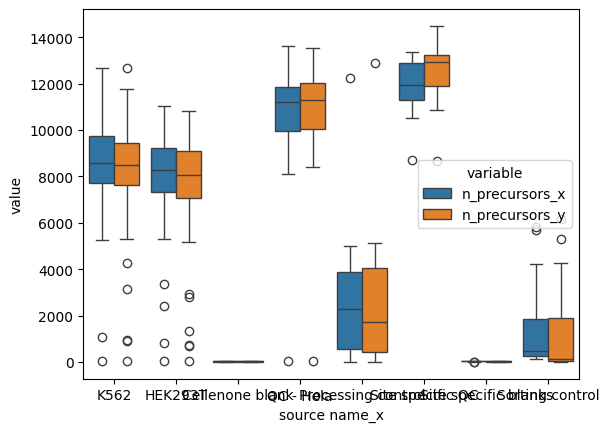

In [27]:
sns.boxplot(
    merged.loc[:,['source name_x', 'sample_name_x', 'n_precursors_x', 'n_precursors_y']].melt(id_vars=['source name_x', 'sample_name_x']),
    x='source name_x',
    y='value',
    hue='variable'
)

In [32]:
merged['diff'] =  merged.apply(lambda x: x['n_precursors_y']-x['n_precursors_x'], axis=1)

<Axes: xlabel='diff', ylabel='source name_x'>

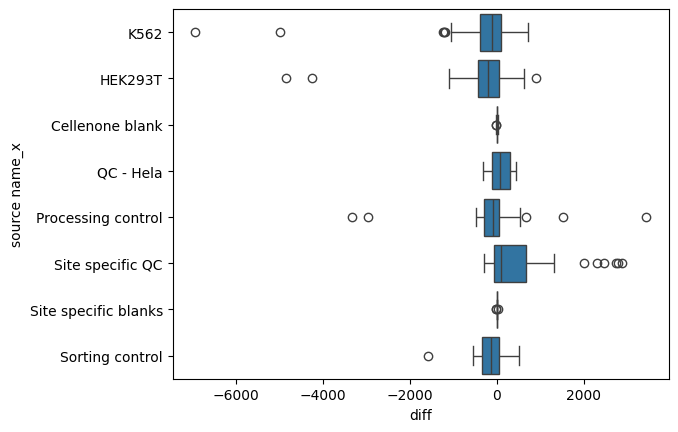

In [33]:
sns.boxplot(
   merged,
   x='diff',
   y='source name_x'
)